# MODELIZACIÓN REGRESIÓN LOSS GIVEN DEFAULT

## IMPORTAR PAQUETES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

#RUTAS
# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ----------USO DE UTILS.PY------------
import sys
from pathlib import Path
# Subir de 03_notebooks a 03_RIESGOS
ROOT = Path.cwd().parent
# Añadir 04_scripts a las rutas de búsqueda
sys.path.insert(0, str(ROOT / "04_scripts"))
#---------------------------------------

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## MODELIZACIÓN REGRESION LOSS GIVEN DEFAULT

### IMPORTAR LOS DATOS

In [2]:
df = pd.read_pickle(ENTRENAMIENTO / "df_tablon_lgd.pkl")

### CREAR X e Y

In [3]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=["target_lgd","target_pd"])
y = df["target_lgd"]
x_train,x_test,y_train,y_val = train_test_split(x, y, test_size=0.3, random_state=42)

### MODELIZAR

#### Crear el pipe y el diccionario de algorimos, parámetros y valores a testar

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor

pipe = Pipeline([('algoritmo', Ridge())])   # el nombre del paso es solo una etiqueta fija

grid = [
    {'algoritmo': [Ridge()],
     'algoritmo__alpha': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]},

    {'algoritmo': [Lasso()],
     'algoritmo__alpha': [0.0001, 0.001, 0.01, 0.05, 0.1]},

    # min_samples_leaf=100: hojas con al menos 100 casos, evita sobreajuste
    # scoring: métrica de la parada temprana, no la del grid
    {'algoritmo': [HistGradientBoostingRegressor(min_samples_leaf=60,
                                                 scoring='neg_mean_absolute_error')],
     'algoritmo__learning_rate': [0.01, 0.025, 0.05, 0.1],
     'algoritmo__max_iter': [50, 100, 200],
     'algoritmo__max_depth': [5, 10, 20],
     'algoritmo__l2_regularization': [0, 0.25, 0.5, 0.75, 1]}
]

#### Optimizar los hiper parámetros

#####  Con grid search

In [5]:
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(pipe, grid, cv=4, scoring='neg_mean_absolute_error', n_jobs=-1)
modelo = grid_search.fit(x_train, y_train)

In [6]:
#quiero tomar los parametros del mejor modelo para usarlo en un nuevo modelo
grid_search.best_params_

{'algoritmo': Lasso(), 'algoritmo__alpha': 0.0001}

In [7]:
# Sin la tasa ni la cuota el grid prefiere Lasso con una penalización mínima; el LGD casi no se puede predecir y da igual el algoritmo
modelo_lgd = Lasso(alpha=0.0001)
modelo_lgd.fit(x_train, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


### EVALUAR

#### Predecir sobre validación

In [8]:
pred = modelo_lgd.predict(x_test)

Al ser un modelo de regresion y estar en porcentaje la variable objetivo no tendria sentido que
tuviera valores por encima de los limites, pero, de todas formas se eliminan los maximos y minimos por si acaso

In [9]:
pred = np.where(pred < 0, 0, pred)  # reemplazar predicciones negativas por 0
pred = np.where(pred > 1, 1, pred)  # reemplazar predicciones mayores a 1 por 1

#### Evaluar sobre validación

In [10]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_val,pred)

0.08846203401346141

### REPORTING DEL MODELO

Podemos analizarlo gráficamente con gráficos de residuos.

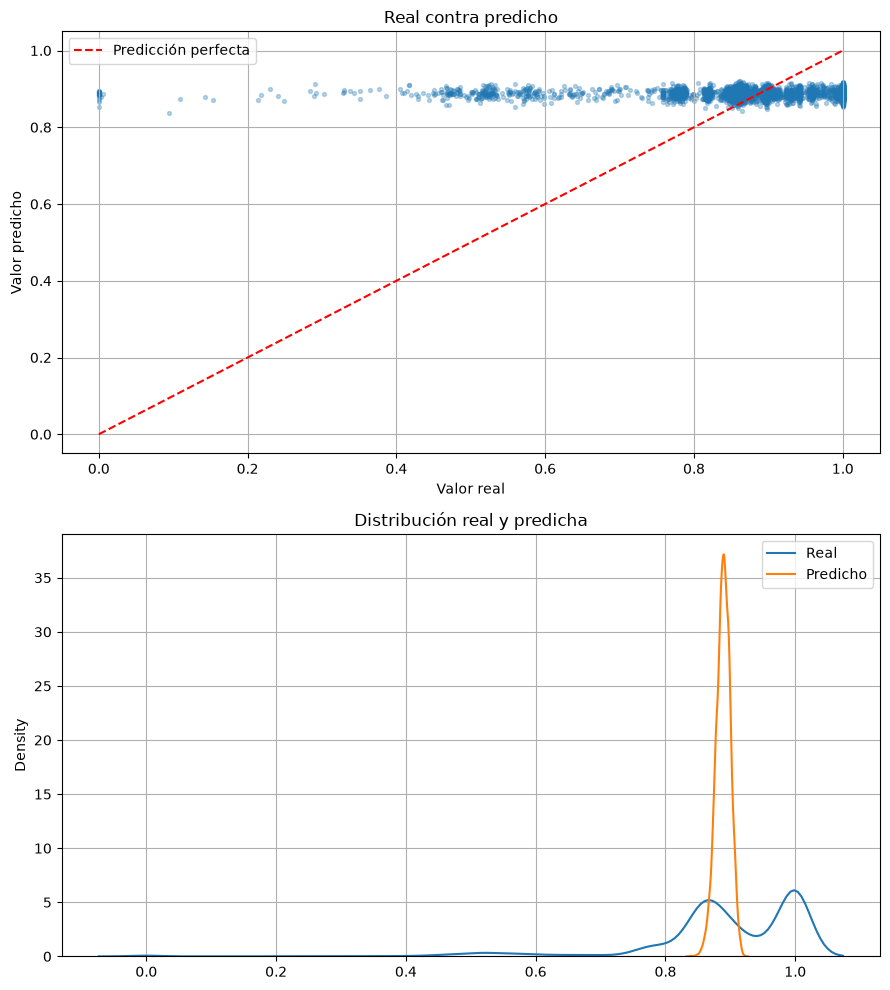

MAE: 0.088  |  error medio sobre el real medio: 9.9%


,casos,real_medio,pred_medio,error_medio
"(-0.001, 0.854]",993,0.705,0.887,0.182
"(0.854, 0.867]",993,0.860,0.889,0.029
"(0.867, 0.942]",993,0.901,0.888,0.020
"(0.942, 1.0]",1986,0.996,0.890,0.106


In [11]:
from utils import reporting_regresion
reporting_regresion(y_val, pred)


Cuando las pérdidas reales son altas, el modelo predice bien. Para los casos con pérdidas más bajas, el modelo es bastante conservador: sus predicciones se mueven en un rango estrecho, en torno a 0,9, como muestra el KDE. Esto ocurre porque, con las variables disponibles, el modelo no logra distinguir bien a unos clientes de otros, y ante esa duda se acerca al valor típico de los datos de entrenamiento, que está cerca de la mediana.

Para comprobarlo, se comparó su error (0,0885) con el de una predicción constante que le asigna a todos el LGD típico (0,0879). Son prácticamente iguales: con estos datos, el modelo no mejora esa referencia.

In [12]:
# ¿Qué error tendría un "modelo" que le dice lo mismo a todos los clientes?
# Se predice, para todos, el LGD típico del entrenamiento (la mediana).
# np.full repite ese valor tantas veces como clientes hay en la validación.
# Si el modelo real no baja de este error, no está aprendiendo nada útil.
mean_absolute_error(y_val, np.full(len(y_val), y_train.median()))

0.08786208784667549

## PROBANDO OTRAS OPCIONES

#### 1) Antes de nada: cuántos clientes hay en cada tramo del LGD real

Si la mayoría de los clientes está cerca de 0,9, un modelo que prediga siempre un valor parecido tendrá un error bajo sin aprender nada. Se cuentan los clientes por tramos de ancho fijo para comprobar si hay pocos ejemplos de pérdidas bajas.

In [13]:
cortes = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

conteo = pd.DataFrame({
    'entrenamiento': pd.cut(y_train, cortes, include_lowest=True).value_counts(sort=False),
    'validacion': pd.cut(y_val, cortes, include_lowest=True).value_counts(sort=False)})

conteo['% entrenamiento'] = (conteo['entrenamiento'] / conteo['entrenamiento'].sum() * 100).round(1)
conteo

,entrenamiento,validacion,% entrenamiento
target_lgd,,,
"(-0.001, 0.1]",48,22,0.400
"(0.1, 0.2]",9,3,0.100
"(0.2, 0.3]",6,9,0.100
"(0.3, 0.4]",40,11,0.300
"(0.4, 0.5]",167,66,1.400
"(0.5, 0.6]",409,154,3.500
"(0.6, 0.7]",123,66,1.100
"(0.7, 0.8]",626,278,5.400
"(0.8, 0.9]",4800,2011,41.400


**Resultado.** El 87,6 % de los clientes de entrenamiento tiene un LGD entre 0,8 y 1, y solo el 2,4 % pierde la mitad o menos. En validación hay unos 95 clientes en esa zona baja, muy pocos para medir el error con precisión.

**Conclusión.** La hipótesis se confirma: hay muy pocos ejemplos de pérdidas bajas, así que el modelo no tiene de dónde aprender qué distingue a esos clientes y predice siempre un valor cercano al típico. Este es un límite de los datos, no un fallo de programación.

#### 2) ¿El modelo sirve para estimar el LGD de grupos de clientes?

Aunque el modelo no distinga bien a cada cliente, para las provisiones del banco importa más acertar el LGD promedio de grupos parecidos. Se agrupan los clientes de validación por rating y se compara el LGD real medio con el predicho medio. Si se parecen, el modelo sirve para estimar pérdidas por grupo.

In [14]:
# El rating viene escalado de 0 a 1: se convierte de nuevo a letra (0 es A, 1 es G)
letra = (x_test['rating_scaled'] * 6).round().astype(int).map(dict(enumerate('ABCDEFG')))

por_rating = (pd.DataFrame({'rating': letra.values, 'real': y_val.values, 'pred': pred})
                .groupby('rating')
                .agg(clientes=('real', 'size'),
                     real_medio=('real', 'mean'),
                     pred_medio=('pred', 'mean'))
                .round(3))

# Diferencia entre lo que predice el modelo y lo que pasó de verdad
por_rating['diferencia'] = (por_rating['pred_medio'] - por_rating['real_medio']).round(3)
por_rating

,clientes,real_medio,pred_medio,diferencia
rating,,,,
A,263,0.906,0.894,-0.012
B,968,0.896,0.892,-0.004
C,1597,0.888,0.890,0.002
D,1096,0.894,0.887,-0.007
E,686,0.889,0.885,-0.004
F,269,0.885,0.883,-0.002
G,86,0.893,0.880,-0.013


### Resultados de las pruebas

**Por rating.** El LGD real medio es casi igual en todos los ratings (de 0,88 a 0,91), y el predicho también (de 0,880 a 0,894). El modelo acierta el promedio de cada grupo, pero solo porque el LGD no cambia según el rating. No es una señal de que el modelo distinga bien, sino de que no hay diferencias que distinguir con estas variables.

### Conclusión

Con las variables disponibles al conceder el préstamo no se puede explicar cuánto se recupera después de un impago. El modelo de LGD equivale en la práctica a asignar un valor fijo cercano al 89 %. Es un límite de los datos y no un fallo de programación. Se mantiene el modelo para completar la cadena PD, EAD y LGD, y la pérdida esperada queda determinada sobre todo por el PD y el EAD.